In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from spacy import displacy
from IPython.display import HTML, display
from pathlib import Path
from matplotlib.patches import Patch


# Get the current working directory of the notebook
notebook_dir = os.getcwd()
# Add the parent directory to the system path
sys.path.append(os.path.join(notebook_dir, '../'))

from data_processing import DataProcessing


In [2]:
pd.set_option('max_colwidth', 800)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
base_data_path = DataProcessing.load_base_data_path(notebook_dir)
llm_results_path = 'classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/averaged/in_domain/llm/'
results_path = os.path.join(base_data_path, llm_results_path)
results_path

'/Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/notebook_experiments/../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/averaged/in_domain/llm/'

## Base Results

In [4]:
llm_results_path = Path(results_path)

models = [
    "gpt-oss-20b",
    "llama-3.3-70b-instruct",
    "mistral-small-3.1",
]

# Load test averages for all available prompts and models
results = []

for model in models:
    model_path = llm_results_path / model

    if not model_path.exists():
        print(f"Missing model directory: {model_path}")
        continue

    for prompt_dir in sorted(model_path.iterdir()):
        if not prompt_dir.is_dir():
            continue

        metrics_file = prompt_dir / "test" / "mean_std.csv"

        if not metrics_file.exists():
            print(f"Missing: {metrics_file}")
            continue

        df = pd.read_csv(metrics_file)
        df.insert(0, "prompt_type", prompt_dir.name)
        df.insert(0, "model", model)
        results.append(df)

llm_test_averages = pd.concat(results, ignore_index=True)

display(llm_test_averages)


,model,prompt_type,metric,mean,std,mean_pm_std
0,gpt-oss-20b,chain-of-thought,train_accuracy,NaN,NaN,nan ± nan
1,gpt-oss-20b,chain-of-thought,val_accuracy,NaN,NaN,nan ± nan
2,gpt-oss-20b,chain-of-thought,test_accuracy,0.859072,0.000489,0.8591 ± 0.0005
3,gpt-oss-20b,chain-of-thought,precision_class_0,0.894645,0.002361,0.8946 ± 0.0024
4,gpt-oss-20b,chain-of-thought,precision_class_1,0.826358,0.002146,0.8264 ± 0.0021
5,gpt-oss-20b,chain-of-thought,recall_class_0,0.825793,0.003166,0.8258 ± 0.0032
6,gpt-oss-20b,chain-of-thought,recall_class_1,0.895000,0.003004,0.8950 ± 0.0030
7,gpt-oss-20b,chain-of-thought,f1_class_0,0.858835,0.000776,0.8588 ± 0.0008
8,gpt-oss-20b,chain-of-thought,f1_class_1,0.859305,0.000501,0.8593 ± 0.0005
9,gpt-oss-20b,chain-of-thought,tn,2318.000000,8.888194,2318.0000 ± 8.8882


## Convert Table to LaTex

In [5]:

# Display the combined test averages as a DataFrame
display(llm_test_averages)

# Convert the DataFrame to LaTeX
latex_table = llm_test_averages.to_latex(
    index=False,
    escape=True,
    float_format="%.4f",
    caption="LLM sentence classification test results averaged across seeds.",
    label="tab:llm_test_averages",
)

print(latex_table)


,model,prompt_type,metric,mean,std,mean_pm_std
0,gpt-oss-20b,chain-of-thought,train_accuracy,NaN,NaN,nan ± nan
1,gpt-oss-20b,chain-of-thought,val_accuracy,NaN,NaN,nan ± nan
2,gpt-oss-20b,chain-of-thought,test_accuracy,0.859072,0.000489,0.8591 ± 0.0005
3,gpt-oss-20b,chain-of-thought,precision_class_0,0.894645,0.002361,0.8946 ± 0.0024
4,gpt-oss-20b,chain-of-thought,precision_class_1,0.826358,0.002146,0.8264 ± 0.0021
5,gpt-oss-20b,chain-of-thought,recall_class_0,0.825793,0.003166,0.8258 ± 0.0032
6,gpt-oss-20b,chain-of-thought,recall_class_1,0.895000,0.003004,0.8950 ± 0.0030
7,gpt-oss-20b,chain-of-thought,f1_class_0,0.858835,0.000776,0.8588 ± 0.0008
8,gpt-oss-20b,chain-of-thought,f1_class_1,0.859305,0.000501,0.8593 ± 0.0005
9,gpt-oss-20b,chain-of-thought,tn,2318.000000,8.888194,2318.0000 ± 8.8882


\begin{table}
\caption{LLM sentence classification test results averaged across seeds.}
\label{tab:llm_test_averages}
\begin{tabular}{lllrrl}
\toprule
model & prompt\_type & metric & mean & std & mean\_pm\_std \\
\midrule
gpt-oss-20b & chain-of-thought & train\_accuracy & NaN & NaN & nan ± nan \\
gpt-oss-20b & chain-of-thought & val\_accuracy & NaN & NaN & nan ± nan \\
gpt-oss-20b & chain-of-thought & test\_accuracy & 0.8591 & 0.0005 & 0.8591 ± 0.0005 \\
gpt-oss-20b & chain-of-thought & precision\_class\_0 & 0.8946 & 0.0024 & 0.8946 ± 0.0024 \\
gpt-oss-20b & chain-of-thought & precision\_class\_1 & 0.8264 & 0.0021 & 0.8264 ± 0.0021 \\
gpt-oss-20b & chain-of-thought & recall\_class\_0 & 0.8258 & 0.0032 & 0.8258 ± 0.0032 \\
gpt-oss-20b & chain-of-thought & recall\_class\_1 & 0.8950 & 0.0030 & 0.8950 ± 0.0030 \\
gpt-oss-20b & chain-of-thought & f1\_class\_0 & 0.8588 & 0.0008 & 0.8588 ± 0.0008 \\
gpt-oss-20b & chain-of-thought & f1\_class\_1 & 0.8593 & 0.0005 & 0.8593 ± 0.0005 \\
gpt-oss-2

## Zero-Shot + Few-Shot + CoT

,model,prompt_type,test_accuracy,test_accuracy_std,macro_f1,macro_f1_std,n_seeds,label
0,gpt-oss-20b,chain-of-thought,0.859072,0.000489,0.859070,0.000490,3,GPT-OSS-20B\nCoT
1,gpt-oss-20b,zero-shot,0.855866,0.004271,0.855782,0.004294,3,GPT-OSS-20B\nZS
2,llama-3.3-70b-instruct,chain-of-thought,0.888663,NaN,0.888649,NaN,1,Llama-3.3-70B\nCoT
3,llama-3.3-70b-instruct,zero-shot,0.864373,0.006999,0.863918,0.007038,3,Llama-3.3-70B\nZS
4,mistral-small-3.1,chain-of-thought,0.848167,0.023352,0.847077,0.022586,3,Mistral-Small-3.1\nCoT
5,mistral-small-3.1,zero-shot,0.824363,0.001796,0.823472,0.001847,3,Mistral-Small-3.1\nZS


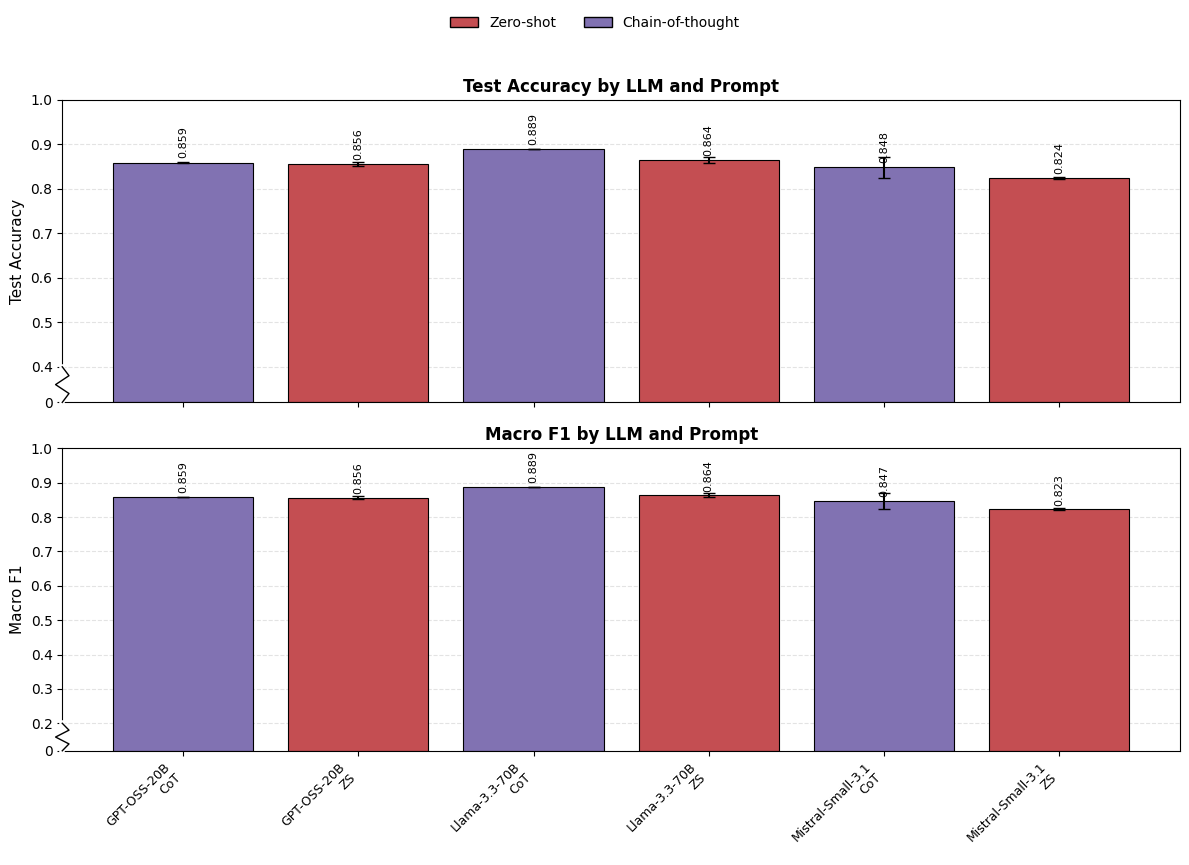

In [7]:
# =====================================================
# Configuration
# =====================================================

models = [
    "gpt-oss-20b",
    "llama-3.3-70b-instruct",
    "mistral-small-3.1",
]

model_labels = {
    "gpt-oss-20b": "GPT-OSS-20B",
    "llama-3.3-70b-instruct": "Llama-3.3-70B",
    "mistral-small-3.1": "Mistral-Small-3.1",
}

prompt_labels = {
    "zero-shot": "ZS",
    "chain-of-thought": "CoT",
}

prompt_colors = {
    "zero-shot": "#C44E52",
    "chain-of-thought": "#8172B2",
}

# =====================================================
# Locate Experiment Directory
# =====================================================

from pathlib import Path

llm_results_dir = Path(results_path)
experiment_dir = llm_results_dir.parents[2]

# =====================================================
# Load Per-Seed Test Results
# =====================================================

records = []

for seed in [3, 7, 33]:
    seed_dir = experiment_dir / f"seed{seed}" / "in_domain" / "llm"

    for model in models:
        model_dir = seed_dir / model

        if not model_dir.exists():
            continue

        for prompt_dir in model_dir.iterdir():
            if prompt_dir.name not in prompt_labels:
                continue

            metrics_file = (
                prompt_dir / "test" /
                f"metrics_summary_{model}_{prompt_dir.name}.csv"
            )

            if not metrics_file.exists():
                continue

            df = pd.read_csv(metrics_file)

            if df.empty:
                continue

            for _, row in df.iterrows():
                records.append({
                    "seed": seed,
                    "model": model,
                    "prompt_type": prompt_dir.name,
                    "test_accuracy": row["test_accuracy"],
                    "macro_f1": np.mean([
                        row["f1_class_0"],
                        row["f1_class_1"],
                    ]),
                })

seed_results = pd.DataFrame(records)

if seed_results.empty:
    raise FileNotFoundError(
        f"No zero-shot or CoT test results found under {experiment_dir}"
    )

# =====================================================
# Average Metrics Across Available Seeds
# =====================================================

summary = (
    seed_results
    .groupby(["model", "prompt_type"], as_index=False)
    .agg(
        test_accuracy=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        macro_f1=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        n_seeds=("seed", "nunique"),
    )
)

summary["label"] = summary.apply(
    lambda r: (
        f"{model_labels[r['model']]}\n"
        f"{prompt_labels[r['prompt_type']]}"
    ),
    axis=1,
)

display(summary)

# =====================================================
# Plot Helper: Broken Y-Axis
# =====================================================

GAP = 0.08
x = np.arange(len(summary))
colors = [prompt_colors[p] for p in summary["prompt_type"]]

def add_y_axis_break(ax, y0, y1, width=0.006, n_zigs=3):
    ax.plot(
        [0, 0], [y0, y1],
        transform=ax.transAxes,
        color="white",
        linewidth=4,
        clip_on=False,
        zorder=10,
    )

    ys = np.linspace(y0, y1, n_zigs + 2)
    xs = [0] + [
        -width if i % 2 == 0 else width
        for i in range(1, n_zigs + 1)
    ] + [0]

    ax.plot(
        xs, ys,
        transform=ax.transAxes,
        color="black",
        linewidth=1,
        clip_on=False,
        zorder=11,
    )

def plot_broken_panel(
    ax, values, stds, lower, ylabel, title, upper=1.0
):
    values = np.asarray(values, dtype=float)
    stds = np.asarray(stds, dtype=float)

    def convert(v):
        return GAP + (np.asarray(v) - lower)

    heights = convert(values)

    bars = ax.bar(
        x,
        heights,
        yerr=stds,
        color=colors,
        edgecolor="black",
        linewidth=0.8,
        capsize=4,
    )

    top = convert(upper)
    ax.set_ylim(0, top)

    ticks = np.round(np.arange(lower, upper + 1e-9, 0.1), 1)
    ax.set_yticks([0] + list(convert(ticks)))
    ax.set_yticklabels(["0"] + [f"{t:.1f}" for t in ticks])

    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90,
        )

    add_y_axis_break(ax, y0=0, y1=GAP / top)

# =====================================================
# Create Figure
# =====================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8.5),
    sharex=True,
)

plot_broken_panel(
    axes[0],
    summary["test_accuracy"],
    summary["test_accuracy_std"].fillna(0),
    lower=0.40,
    ylabel="Test Accuracy",
    title="Test Accuracy by LLM and Prompt",
)

plot_broken_panel(
    axes[1],
    summary["macro_f1"],
    summary["macro_f1_std"].fillna(0),
    lower=0.20,
    ylabel="Macro F1",
    title="Macro F1 by LLM and Prompt",
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(
    summary["label"],
    rotation=45,
    ha="right",
    fontsize=9,
)

# =====================================================
# Legend
# =====================================================

legend_handles = [
    Patch(
        facecolor=prompt_colors[prompt],
        edgecolor="black",
        label=label,
    )
    for prompt, label in [
        ("zero-shot", "Zero-shot"),
        ("chain-of-thought", "Chain-of-thought"),
    ]
    if prompt in summary["prompt_type"].unique()
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(legend_handles),
    frameon=False,
    fontsize=10,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# plt.savefig(
#     "llm_zero_shot_cot_test_comparison.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()